In [13]:
import pandas as pd

readings = pd.read_json("sample_data/readings.json")
readings.head(9)

,reading_id,device_id,type,value,unit,status,measured_at,received_at
0,c920aae9-9328-4178-81bc-32735b5eed09,07a0ca6e-0822-48f3-ac03-1199972a8469,heart_rate,47.000,BPM,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:02+00:00
1,6650bc24-f84b-441f-8466-b04d2c0c9e4b,07a0ca6e-0822-48f3-ac03-1199972a8469,skin_conductance,1.300,µS,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:02+00:00
2,cd104ac6-46c2-446e-b0e2-8479a8f0d513,07a0ca6e-0822-48f3-ac03-1199972a8469,movement,0.031,g,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:02+00:00
3,43b7a3a6-9a8d-4a03-980d-7b71d8f56413,23b8c1e9-3924-46de-beb1-3b9046685257,heart_rate,62.000,BPM,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:03+00:00
4,759cde66-bacf-43d0-8b1f-9163ce9ff57f,23b8c1e9-3924-46de-beb1-3b9046685257,skin_conductance,1.720,µS,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:03+00:00
5,ec1b8ca1-f91e-4d4c-9ff4-9b7889463e85,23b8c1e9-3924-46de-beb1-3b9046685257,movement,0.021,g,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:03+00:00
6,77a11b8e-4d9f-4527-83dd-6a1e6dc1fead,b38a088c-a65e-4389-b74d-0fb132e70629,heart_rate,56.000,BPM,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:04+00:00
7,a6fe4211-7fe8-4570-8fd0-da660a444a9f,b38a088c-a65e-4389-b74d-0fb132e70629,skin_conductance,2.280,µS,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:04+00:00
8,bcfc1f9f-0af6-49dd-a381-bbd7271ffe38,b38a088c-a65e-4389-b74d-0fb132e70629,movement,0.025,g,valid,2026-10-28 23:00:00+00:00,2026-10-28 23:00:04+00:00


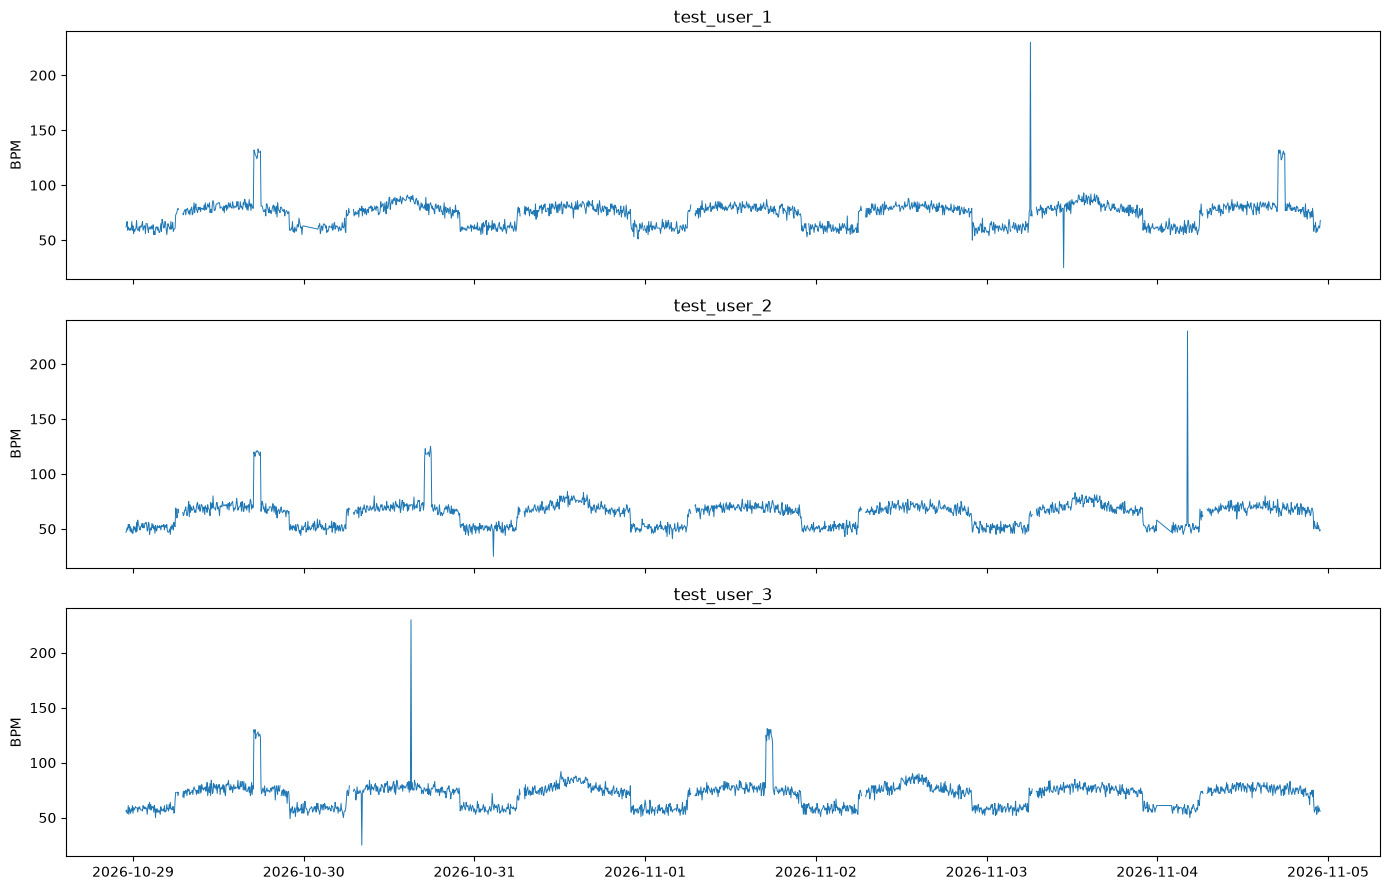

In [14]:
import matplotlib.pyplot as plt

users = pd.read_json("sample_data/users.json")
hr_all = readings[readings["type"] == "heart_rate"].merge(users, on="device_id").sort_values("measured_at")

fig, axes = plt.subplots(len(users), 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, (name, data) in zip(axes, hr_all.groupby("username")):
    ax.plot(data["measured_at"], data["value"], linewidth=0.7)
    ax.set_title(name)
    ax.set_ylabel("BPM")
plt.tight_layout()

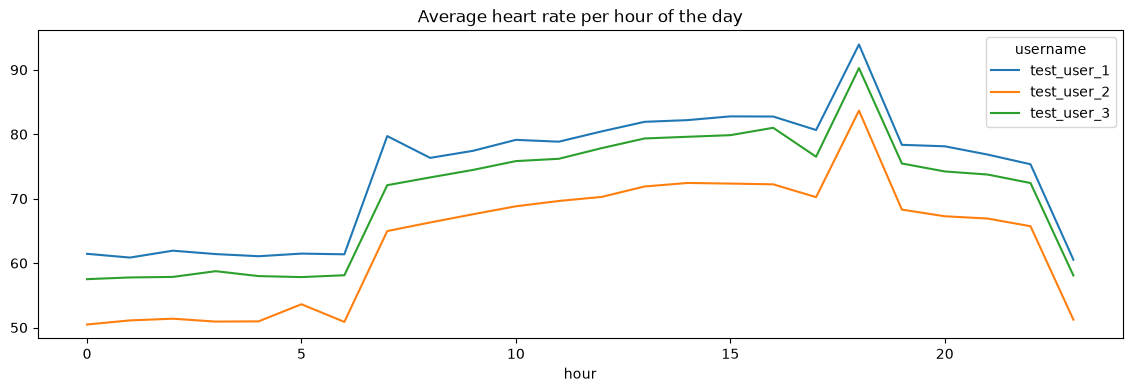

In [15]:
hr_all["hour"] = hr_all["measured_at"].dt.tz_convert("Europe/Amsterdam").dt.hour
hr_all.groupby(["hour", "username"])["value"].mean().unstack().plot(figsize=(14, 4), title="Average heart rate per hour of the day");

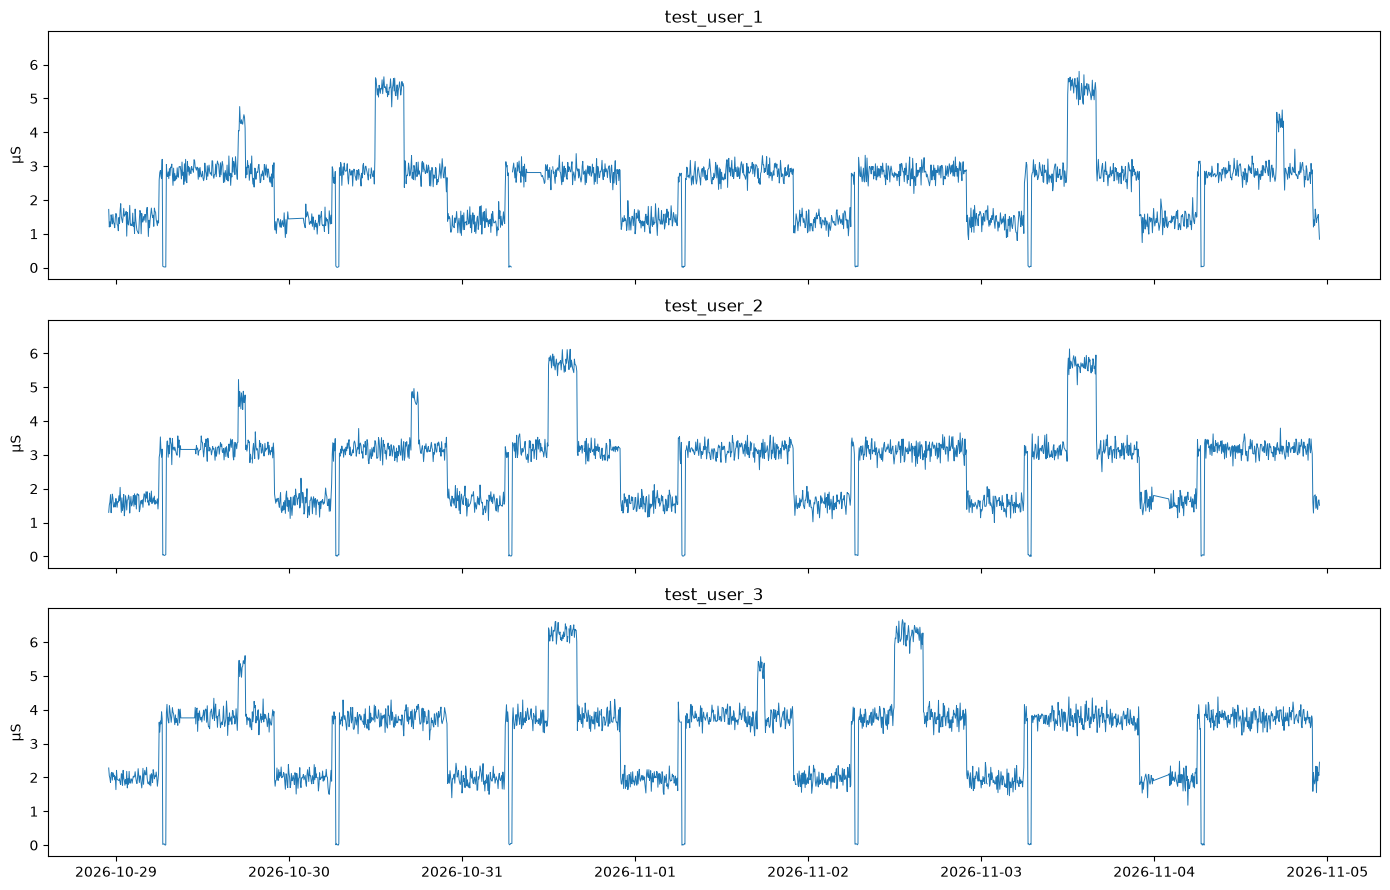

In [ ]:
import matplotlib.pyplot as plt

users = pd.read_json("sample_data/users.json")
hr_all = readings[readings["type"] == "skin_conductance"].merge(users, on="device_id").sort_values("measured_at")

fig, axes = plt.subplots(len(users), 1, figsize=(14, 9), sharex=True, sharey=True)
for ax, (name, data) in zip(axes, hr_all.groupby("username")):
    ax.plot(data["measured_at"], data["value"], linewidth=0.7)
    ax.set_title(name)
    fig, axes = plt.subplots(1, len(users), figsize=(14, 4), sharex=True, sharey=True)
plt.tight_layout()